<!--

    Gaia Data Processing and Analysis Consortium (DPAC) 
    Co-ordination Unit 9 Work Package 930
    
    (c) 2005-2025 Gaia DPAC
    
    This program is free software: you can redistribute it and/or modify
    it under the terms of the GNU General Public License as published by
    the Free Software Foundation, either version 3 of the License, or
    (at your option) any later version.

    This program is distributed in the hope that it will be useful,
    but WITHOUT ANY WARRANTY; without even the implied warranty of
    MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
    GNU General Public License for more details.

    You should have received a copy of the GNU General Public License
    along with this program.  If not, see <https://www.gnu.org/licenses/>.
    -->
    
The bulk of Gaia XP mean spectra at Gaia DR3 are provided in a parametric "continuous" representational form (as opposed to conventional sampled form, i.e. fluxes in wavelength bins) in table `gaiadr3.xp_continuous_mean_spectrum`. Utilities for handling this form, including conversion to sampled form and plotting, are provided in a bespoke Python package [GaiaXPy](https://gaia-dpci.github.io/GaiaXPy-website/) which is available on this platform. A small subset of the XP spectra are provided also in sampled form in table `gaiadr3.xp_sampled_mean_spectrum` but these are for illustrative purposes only: users are strongly encouraged to familiarise themselves and work with the continuous representation, not least in order to handle correctly the statistical uncertainties inherent to the data.

To access GaiaXPy on this platform simply import the package as follows:

    import gaiaxpy

then all classes and utility functions etc. will be available.


In [1]:
import time

Beginning the initilization of a spark cluster with 10 pods, 5 cores/pod and 70g mem/pod


25/07/30 09:35:34 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/07/30 09:35:35 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


Completed initialisation
Setting up SparkSQL
Setting up dataset Gaia DR3 with 4 databases gaiadr3, gaiadr3ssd, gaiaedr3ssd, gaiaedr3


mkdir -p failed for path /home/jovyan/.config/matplotlib: [Errno 20] Not a directory: '/home/jovyan/.config/matplotlib'
Matplotlib created a temporary cache directory at /tmp/matplotlib-fxbi4vgt because there was an issue with the default path (/home/jovyan/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


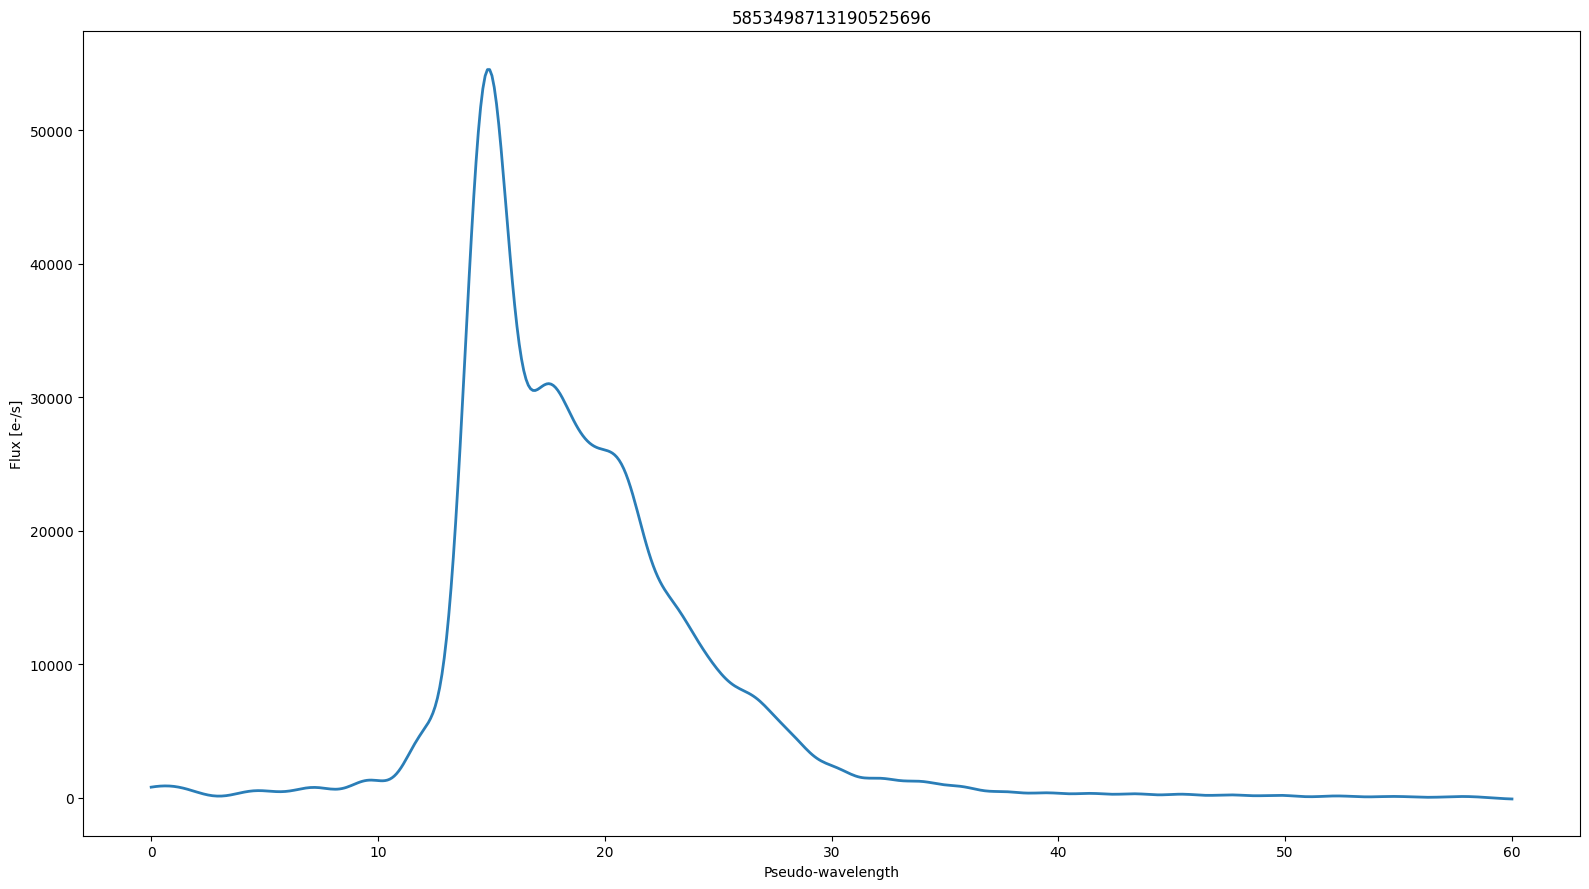

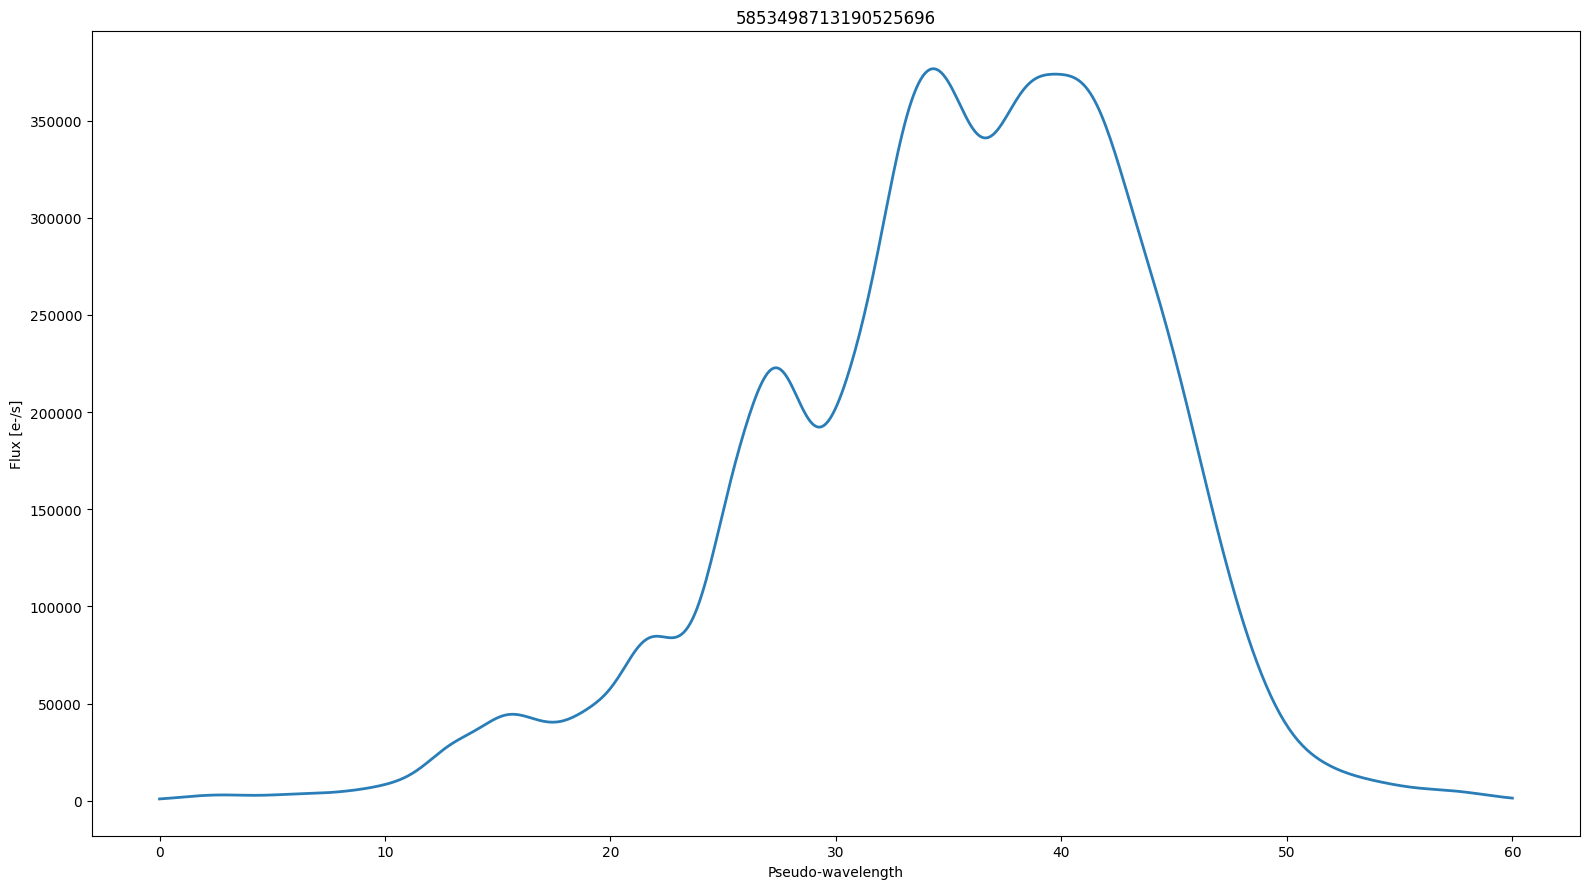

In [ ]:
# Import the spark config
from spark_setup import SparkSetup
from setup_data_gaia_dr3 import SetupDataGaiaDR3

# Request more memory than default import to handle large XP spectra data
spark_setup = SparkSetup(pods=10, cpu=5, mem=70, data_setup=SetupDataGaiaDR3)
spark = spark_setup.get_spark_session()

# utility code set-up
from gaiaxpy import plot_spectra, convert

# XP products available in Gaia DR3, so set the default database context accordingly for convenience
spark.sql('USE gaiadr3')

# grab an example spectrum from the table
continuous_df = spark.sql('SELECT * FROM xp_continuous_mean_spectrum WHERE source_id = 5853498713190525696')
# ... this source identifier corresponds to Proxima Cen (= Alpha Cen C, spectral type M5.5V i.e. a mid-M dwarf)

# convert to a Pandas dataframe for GaiaXPy
continuous_spectrum = continuous_df.toPandas()

# convert to sampled form:
sampled_spectrum, sampling = convert(continuous_spectrum, save_file = False)
    
# plot to sanity check:
plot_spectra(sampled_spectrum, sampling = sampling, multi=False, show_plot=True, output_path=None, legend=True)

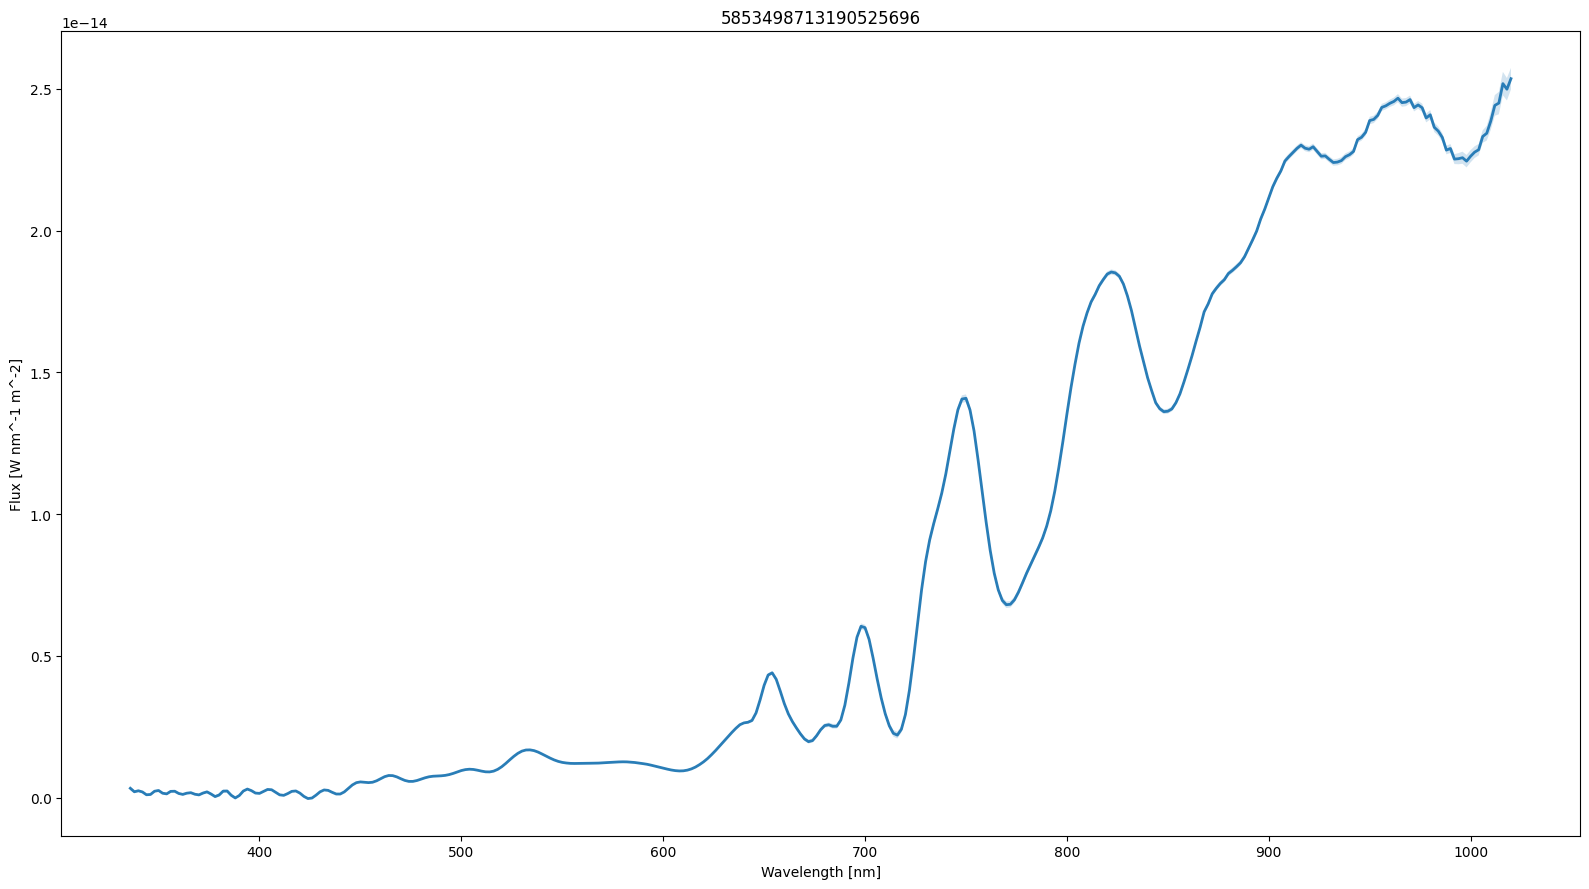

In [3]:
from gaiaxpy import calibrate

# GaiaXPy provides classes and methods to create an externally calibrated single spectrum from the internal XP continuous representation:
calibrated_spectrum, sampling = calibrate(continuous_spectrum, save_file = False)

# plot it
plot_spectra(calibrated_spectrum, sampling = sampling, legend = False)

The code in the following cells illustrates a workflow where we trawl through the a large XP spectral data looking for spectra similar to a high signal-to-noise template example. The implementation takes advantage of the end-user programmability of the distributed query execution engine to return results in a reasonable time. The approach is to look for spectra having the same spectral shape, as expressed in the coefficients of the continuous representation.

In [4]:
import numpy as np
import pandas as pd
from pyspark.sql.functions import pandas_udf
from pyspark.sql import DataFrame
#from scipy.stats import chi

# static constants for use when reconstructing a covariance matrix from the flattened upper-triangular correlation matrix stored in xp_continuous_mean_spectrum
NUM_XP_COEFFS = 55
# these indexes define the column-major positions of the correlation vector elements in the lower triangle of the 2d correlation matrix ...
lower_index = np.tril_indices(NUM_XP_COEFFS,-1)
# ... note that numpy indexing is row-major. The upper triangular index is created from the lower, reflecting across the diagonal,
# by transposing the axes - this results in the required column-major indexing for the upper part
upper_index = (lower_index[1], lower_index[0])
# correlation matrix, empty apart from unity on the diagonal (off-diagonal elements to be filled in on a case-by-case basis)
correlation_matrix = np.diag(np.ones(NUM_XP_COEFFS))

def make_correlation_matrix(correlation_vector : np.ndarray) -> np.ndarray:
    '''
    Returns the fully populated 2d correlation matrix given the flattened, 1d upper-triangular off-diagonal
    elements of the same as persisted in the table of XP continuous representation spectra.
    '''
    # copy in unique, off-diagonal elements from the flattened correlation vector into the 2d-indexed positions
    correlation_matrix[upper_index] = correlation_vector
    correlation_matrix[lower_index] = correlation_vector
    
    # give back the complete correlation matrix
    return correlation_matrix

def make_covariance_matrix(complete_correlation_matrix : np.ndarray, coefficient_error_vector : np.ndarray) -> np.ndarray:
    '''
    Creates the fully reconstructed 2d covariance matrix of an XP continuous representation spectrum given the
    complete 2d correlation matrix and the vector of formal errors on the coefficients. Note that Gaia DPAC CU5 scale 
    predicted coefficient errors by the standard deviation as a post-hoc correction to the formal (sqrt) variances.
    GaiaXPy actually reverses this scaling in computation of the covariance matrix to return the latter as exactly
    that produced as a result of the least-squares solution for the coefficients. Such a de-scaling of the errors
    is not applied here: we assume that the uncertainties are best represented with this scaling intact.
    '''
    # 2d matrix with the errors on the diagonal
    error_matrix = np.diag(coefficient_error_vector)
    
    # from the standard relationship between covariance and correlation
    return error_matrix @ (error_matrix @ complete_correlation_matrix)
    
def xp_mahalanobis_distance(coeff_vector_1 : np.ndarray, covariance_1 : np.ndarray,
        coeff_vector_2 : np.ndarray, error_vector_2 : np.ndarray, correlation_vector_2 : np.ndarray) -> float:
    '''
    Computes the Mahalanobis distance between two XP spectra given template coefficients and fully populated
    covariance for the first, and the data record of the second candidate spectrum, i.e. coefficients, errors and 
    upper-triangular part of the correlation matrix in the continuous representation. The second set of
    coefficients and errors should be scaled to the same flux level as the template spectrum. This means that
    the distance returned quantifies how close the candidate SED shape is to that of the template regardless any
    difference in intrinsic luminosity.
    
    This function uses plain matrix inversion of the combined covariance matrix. This can be numerically unstable
    and result in a negative squared distance resulting in turn in a return value of not-a-number. It is up to 
    the calling application to handle this condition.
    '''
    
    # second covariance matrix
    corr2 = make_correlation_matrix(correlation_vector_2)
    covariance_2 = make_covariance_matrix(corr2, error_vector_2)
    
    # form covariance of the coefficient difference vector as sum of individual covariance 
    cocovar = covariance_1 + covariance_2
    
    # inverse of combined, scaled covariance
    cocovar_inv = np.linalg.inv(cocovar)

    # use these in the computation of the square of the Mahalanobis distance, e.g. see source linked from
    # https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.mahalanobis.html
    delta = coeff_vector_1 - coeff_vector_2
    d = np.sqrt(np.dot(np.dot(delta, cocovar_inv), delta))

    # for identical spectra
    return d
    
def xp_signal_to_noise(coeff : np.ndarray, coeff_err : np.ndarray, n_valid : int) -> float:
    '''
    Computes global signal-to-noise ratio of XP spectra via L2 norms - see De Angeli et al. (2022) Section 5.3.
    Assume this should done using only the N relevenat bases.
    
    Returns: signal-to-noise ratio for the individual band spectrum coefficients and uncertainties
    '''
    
    if not type(n_valid) is int: return 0.0
    
    # signal-to-noise from L2 norm of the XP coefficients
    return np.linalg.norm(coeff[:n_valid]) / np.linalg.norm(coeff_err[:n_valid])

@pandas_udf('float')
def signal_to_noise_pudf(coeffs : pd.Series, coeff_errors : pd.Series, nums_valid : pd.Series) -> pd.Series:
    '''
    Compute a vector of global signal-to-noise estimates for an individual XP band given the basis
    coefficients, their uncertainties, and the number of valid components.
    '''
        
    # simply vectorize by combining series into a single Pandas dataframe object on which the apply method can be invoked
    return pd.concat([coeffs, coeff_errors, nums_valid], axis = 1).apply(lambda row: xp_signal_to_noise(row[0], row[1], row[2]), axis = 1)
    # define a vectorised Pandas UDF against the template for comparison of other spectra against it


def find_similar_continuous_spectra(data_frame : DataFrame, template_df : DataFrame) -> DataFrame:
    '''
    Given data frames defining a large set of XP spectra in continuous representation, 
    and a single template example also in continuous representation, search the former for cases
    similar to the latter. The data frame of the set of spectra being
    searched is annotated with a dissimilarity statistic: the greater the value the more
    dissimilar is the candidate spectrum to the template given. By definition this statistic
    will be zero for the template spectrum if it is present in the set of candidates.
    
    Parameters:
    -----------
    data_frame : DataFrame()
        the data frame encapsulating the set of XP continuous representation spectra to be searched
    template_df : DataFrame()
        the template, also in XP continuous representation encapsulated in a data frame.
        
    return : DataFrame()
        a new data frame annotated with a dissimilarity (increasingly positive) statistic where 
        zero indicates a perfect match.
    '''
    
    # convenience reference to template as a Row object:
    template_row = template_df.first()
    
    # extract the template arrays 
    template_bp_coefficients = np.array(template_row['bp_coefficients']).reshape(-1)
    template_bp_coefficient_errors = np.array(template_row['bp_coefficient_errors']).reshape(-1)
    template_bp_correlations = np.array(template_row['bp_coefficient_correlations']).reshape(-1)
    template_rp_coefficients = np.array(template_row['rp_coefficients']).reshape(-1)
    template_rp_coefficient_errors = np.array(template_row['rp_coefficient_errors']).reshape(-1)
    template_rp_correlations = np.array(template_row['rp_coefficient_correlations']).reshape(-1)
    template_gmag = template_row['phot_g_mean_mag']

    # precompute the required vectors and matrices for the template
    bp_correl_mat = make_correlation_matrix(template_bp_correlations)
    template_bp_covariance = make_covariance_matrix(bp_correl_mat, template_bp_coefficient_errors)
    rp_correl_mat = make_correlation_matrix(template_rp_correlations)
    template_rp_covariance = make_covariance_matrix(rp_correl_mat, template_rp_coefficient_errors)

    # filter the given data such that only those sources with S/N ratio of 90% or better are tested for similarity for best reliability
    # N.B. completeness is totally neglected here in this illustrative workflow!
    template_bp_n_rel_bases = template_row['bp_n_relevant_bases']
    template_rp_n_rel_bases = template_row['rp_n_relevant_bases']
    threshold_bp_snr = 0.9 * xp_signal_to_noise(template_bp_coefficients, template_bp_coefficient_errors, template_bp_n_rel_bases)
    threshold_rp_snr = 0.9 * xp_signal_to_noise(template_rp_coefficients, template_rp_coefficient_errors, template_rp_n_rel_bases)
    data_frame = data_frame.filter(signal_to_noise_pudf('bp_coefficients', 'bp_coefficient_errors', 'bp_n_relevant_bases') > threshold_bp_snr)
    data_frame = data_frame.filter(signal_to_noise_pudf('rp_coefficients', 'rp_coefficient_errors', 'rp_n_relevant_bases') > threshold_rp_snr)

    @pandas_udf('float')
    def xp_is_similar(bp_coeffs:pd.Series, bp_coeff_errors:pd.Series, bp_correlations:pd.Series, 
                          rp_coeffs:pd.Series, rp_coeff_errors:pd.Series, rp_correlations:pd.Series,
                          gmags:pd.Series) -> pd.Series:
        '''
        Create a similarity metric for the XP continuous representation coefficients with respect 
        to those of a predefined template. Similarity is based on a combined BP and RP Mahalanobis
        distance between the coefficient sets with full accounting for covariance. Input arguments
        are series of the BP and RP coefficients, errors and correlation vectors as stored in table
        xp_continuous_mean_spectrum. The returned object is a corresponding series of floats of the
        quadrature sum of the BP and RP Mahalanobis distances between each candidate spectrum and
        the static template defined above.
        '''
            
        # initialise the results series
        results = pd.Series(np.full(bp_coeffs.size, 0.0))
    
        # iterate over the data series
        for i in range(bp_coeffs.size):
                
            # normalise the candidate flux coefficients and uncertainties to that of the template
            norm = 10.0**(0.4 * (template_gmag - gmags.iloc[i]))
            bp_coeffs_norm = bp_coeffs.iloc[i] / norm
            bp_coeff_errors_norm = bp_coeff_errors.iloc[i] / norm
            rp_coeffs_norm = rp_coeffs.iloc[i] / norm
            rp_coeff_errors_norm = rp_coeff_errors.iloc[i] / norm
                
            # Mahalanobis distances for the individual BP and RP coefficient sets normalised to the flux level of the template
            bp_mdist = xp_mahalanobis_distance(template_bp_coefficients, template_bp_covariance, bp_coeffs_norm, bp_coeff_errors_norm, bp_correlations.iloc[i])
            rp_mdist = xp_mahalanobis_distance(template_rp_coefficients, template_rp_covariance, rp_coeffs_norm, rp_coeff_errors_norm, rp_correlations.iloc[i])
                
            # combined Mahalanobis distance
            results.iloc[i] = np.sqrt(bp_mdist * bp_mdist + rp_mdist * rp_mdist)
                
        return results
    
    # add in the similarity statistic
    data_frame = data_frame.withColumn('xp_similar', xp_is_similar(
        data_frame.bp_coefficients, data_frame.bp_coefficient_errors, data_frame.bp_coefficient_correlations, 
        data_frame.rp_coefficients, data_frame.rp_coefficient_errors, data_frame.rp_coefficient_correlations, data_frame.phot_g_mean_mag))
        
    # give back the full set filtering out any nulls (which may result from NaN individual Mahalanobis distances)
    return data_frame.filter(data_frame.xp_similar.isNotNull())

Thresholds are 378.3741668701172 556.680322265625


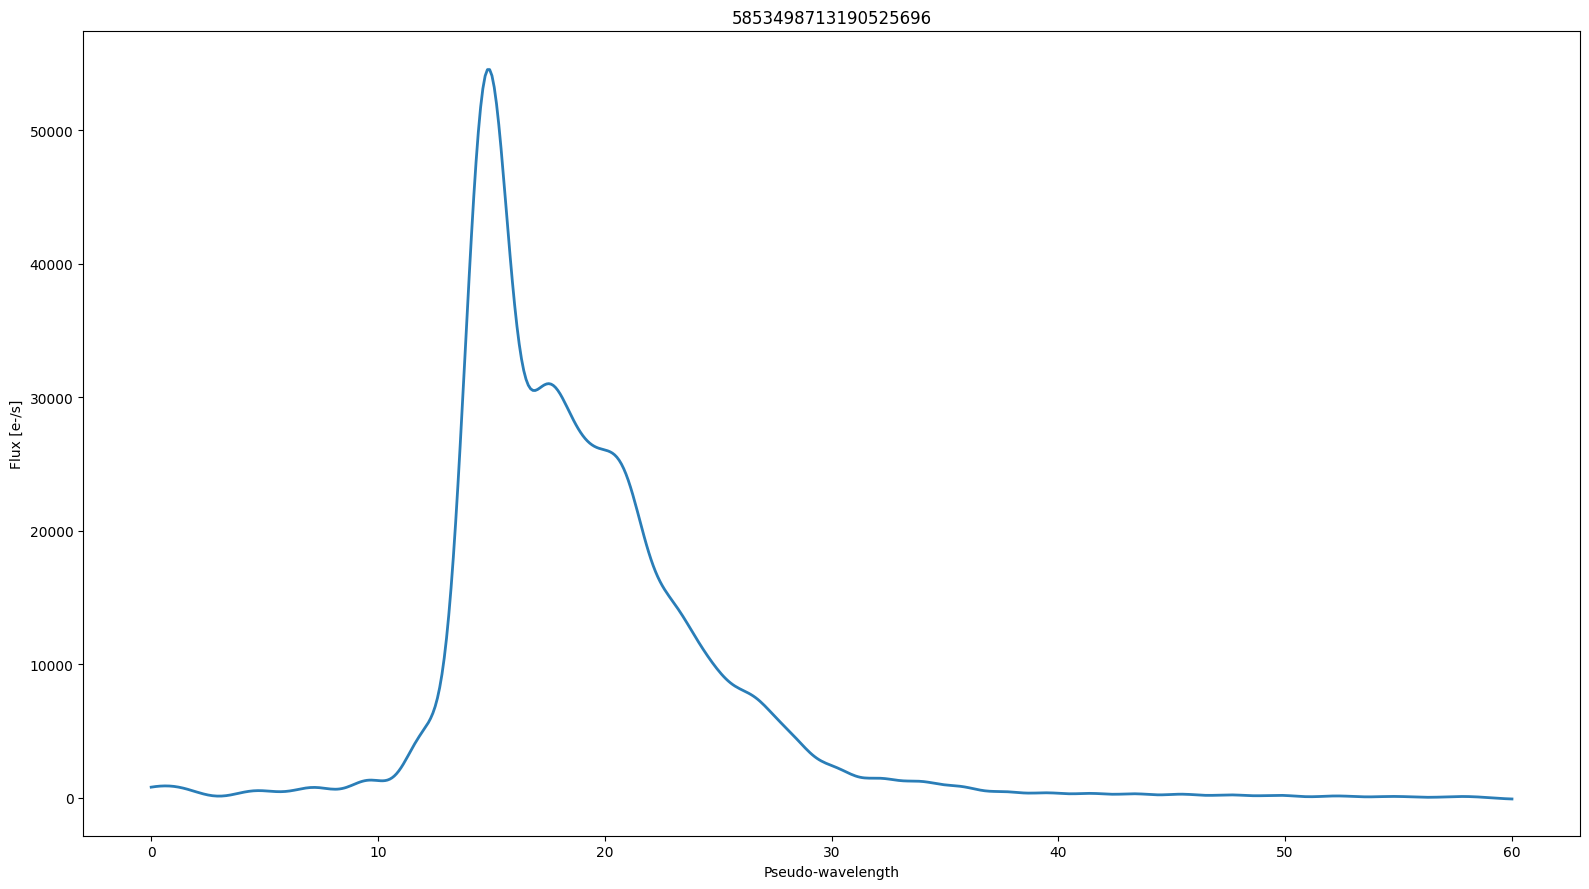

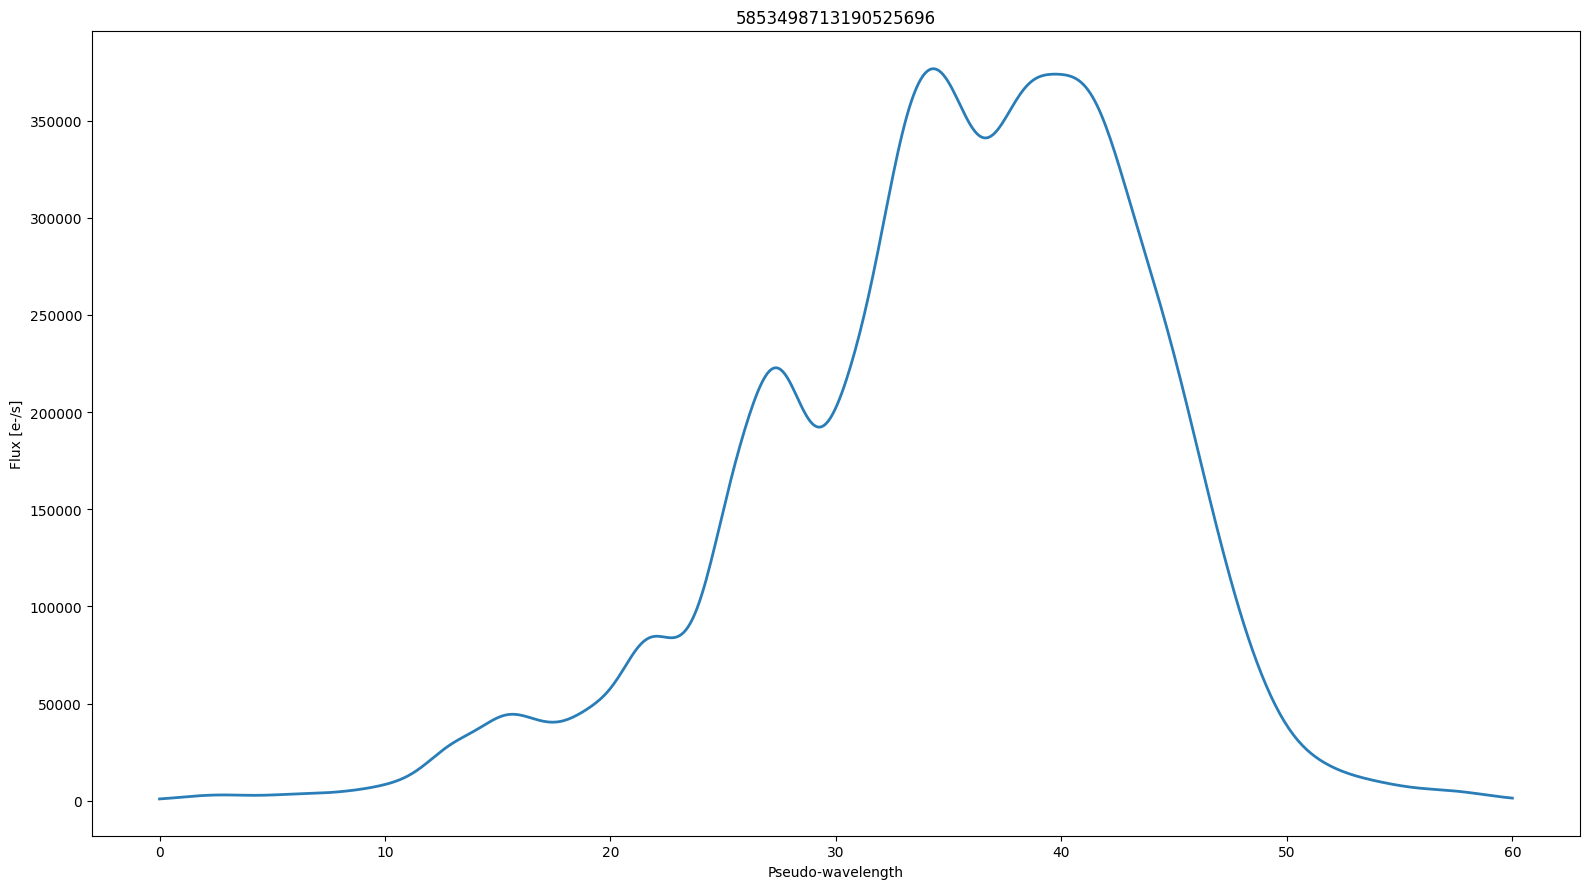

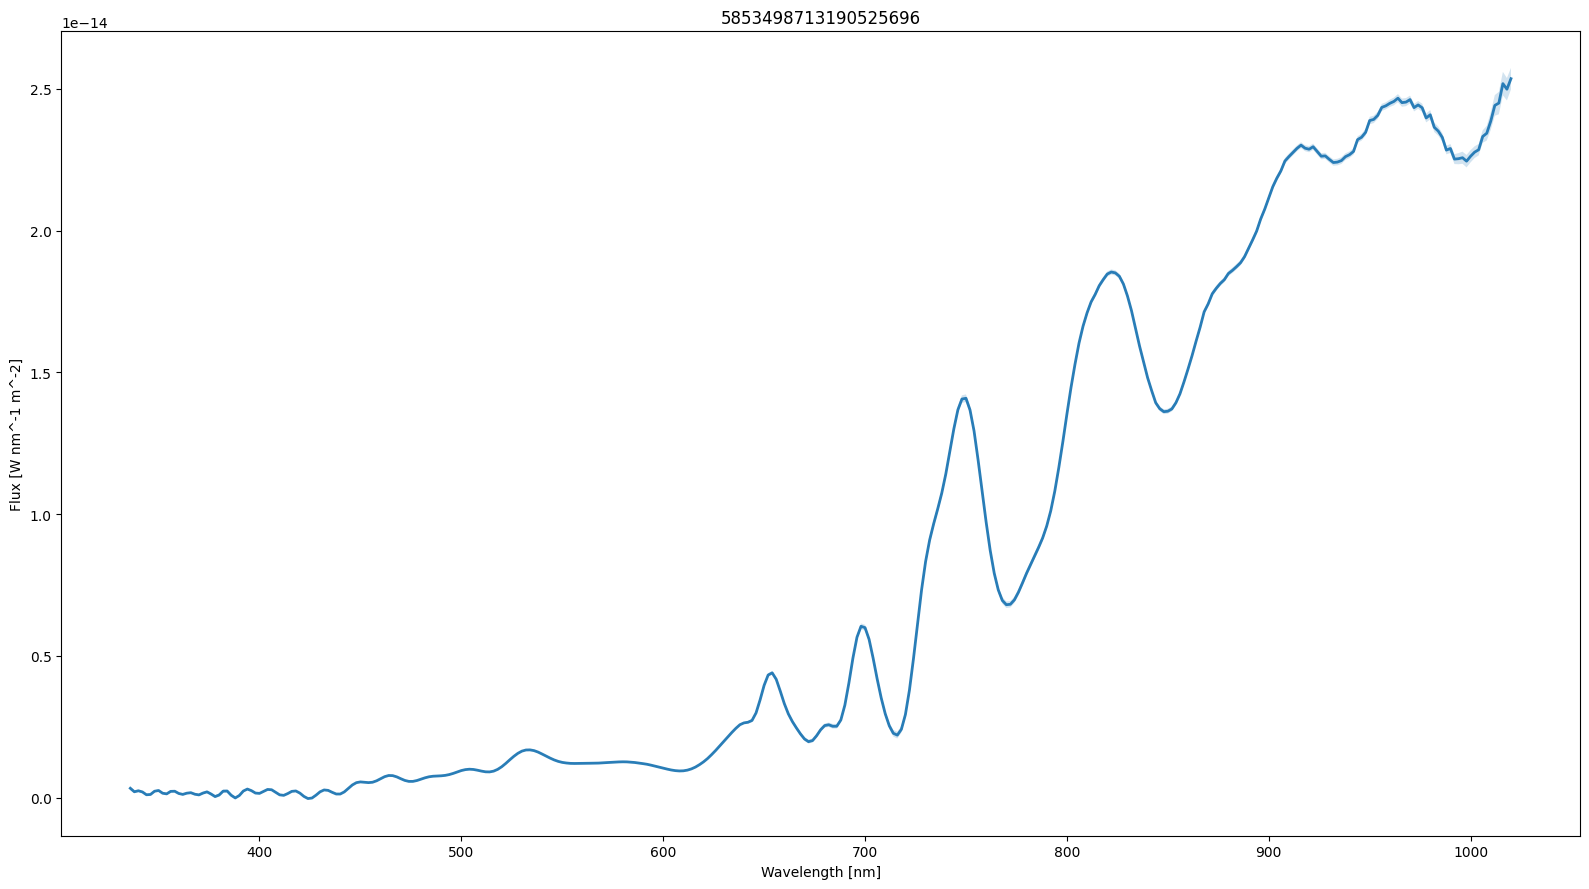

In [5]:
# select a high s/n template for the search, e.g. Proxima Cen
sid = 5853498713190525696

# defined the template data frame
template_df = spark.sql("""
                        SELECT xp.*, g.phot_g_mean_mag, g.phot_bp_mean_flux_over_error, g.phot_rp_mean_flux_over_error
                        FROM xp_continuous_mean_spectrum AS xp 
                        INNER JOIN gaia_source AS g 
                            ON g.source_id = xp.source_id 
                            WHERE g.source_id = %d"""%(sid))

template_row = template_df.first()
thresh_bp = 0.9 * template_row['phot_bp_mean_flux_over_error']
thresh_rp = 0.9 * template_row['phot_rp_mean_flux_over_error']
print(f'Thresholds are {thresh_bp} {thresh_rp}')

continuous_df = spark.sql("""
                        SELECT xp.*, g.phot_g_mean_mag 
                        FROM xp_continuous_mean_spectrum AS xp
                        INNER JOIN gaia_source AS g
                            ON g.source_id = xp.source_id
                          WHERE g.source_id = %d"""%(sid))
continuous_spectrum = continuous_df.limit(1).toPandas()

# convert to sampled form:
sampled_spectrum, sampling = convert(continuous_spectrum, save_file = False)



# plot to sanity check:
plot_spectra(sampled_spectrum, sampling = sampling, multi=False, show_plot=True, output_path=None, legend=True)

# GaiaXPy provides classes and methods to create an externally calibrated single spectrum from the internal XP continuous representation:
calibrated_spectrum, sampling = calibrate(continuous_spectrum, save_file = False)

# plot it
plot_spectra(calibrated_spectrum, sampling = sampling, legend = False)

In [6]:
source_df = spark.sql("""
                        SELECT xp.*, g.phot_g_mean_mag 
                        FROM xp_continuous_mean_spectrum AS xp
                        INNER JOIN gaia_source AS g
                            ON g.source_id = xp.source_id""")

# # get any that are similar and show them
similar_df = find_similar_continuous_spectra(source_df, template_df)

# # results quick-look
similar_df.show()

+-----------------+-------------------+--------------------+---------------------+---------------+-----------------+--------------------------+---------------------+--------------+--------------------+---------------------+---------------------------+-------------------+---------------------+--------------------+---------------------+---------------+-----------------+--------------------------+---------------------+--------------+--------------------+---------------------+---------------------------+-------------------+---------------------+---------------+----------+
|        source_id|        solution_id|bp_basis_function_id|bp_degrees_of_freedom|bp_n_parameters|bp_n_measurements|bp_n_rejected_measurements|bp_standard_deviation|bp_chi_squared|     bp_coefficients|bp_coefficient_errors|bp_coefficient_correlations|bp_n_relevant_bases|bp_relative_shrinking|rp_basis_function_id|rp_degrees_of_freedom|rp_n_parameters|rp_n_measurements|rp_n_rejected_measurements|rp_standard_deviation|rp_chi

In [7]:
# collecting the results to a Pandas data frame collects the results to the driver interpreter process
# so this cell will actually action the trawl on the Spark worker cluster. Be prepared to sit back and wait...
top3_pdf = similar_df.sort(similar_df.xp_similar.asc()).limit(3).toPandas()

# sanity check as required
# z.show(top3_pdf)

In [8]:
top3_pdf

,source_id,solution_id,bp_basis_function_id,bp_degrees_of_freedom,bp_n_parameters,bp_n_measurements,bp_n_rejected_measurements,bp_standard_deviation,bp_chi_squared,bp_coefficients,...,rp_n_rejected_measurements,rp_standard_deviation,rp_chi_squared,rp_coefficients,rp_coefficient_errors,rp_coefficient_correlations,rp_n_relevant_bases,rp_relative_shrinking,phot_g_mean_mag,xp_similar
0,5853498713190525696,4545469030156206080,56,4646,55,4701,19,1.122467,5853.641602,"[56947.03696840172, 13812.466168611605, 6752.4...",...,137,1.315128,9753.001953,"[735186.2157096652, 350804.5610551923, -24394....","[284.91925, 199.77626, 246.6683, 286.87973, 25...","[0.17973025, 0.5096138, -0.258848, -0.17316186...",40,1.000000,8.984749,0.000000
1,5835696657883178752,4545469030156206081,56,2404,55,2459,46,1.172308,3303.830811,"[1157.4956191845727, 333.73079964005694, 102.0...",...,51,1.584294,7919.013184,"[13997.984012988749, 6552.578779437672, -663.6...","[8.21813, 6.2645397, 7.114696, 8.671543, 8.009...","[0.30928564, 0.40806654, -0.21433082, -0.10871...",10,0.999996,13.247912,118.613373
2,4162883930535952640,4545469030156206081,56,2457,55,2512,7,1.068475,2805.004150,"[397.3069166413005, 125.40236289040728, 35.516...",...,23,1.219073,4228.063965,"[4904.017893666165, 2278.2503531414823, -220.6...","[2.4866633, 2.004625, 2.224695, 2.5504253, 2.4...","[0.43315852, 0.30632856, -0.28062198, -0.07761...",16,0.999999,14.388062,120.100441


In [9]:
sources = [row.source_id for row in similar_df.select("source_id").head(3)]
source_ids = tuple(sources) if len(sources) > 1 else f"({sources[0]})"
cdf = spark.sql(f"""
    SELECT * FROM xp_continuous_mean_spectrum 
    WHERE source_id IN {source_ids}
""").toPandas()


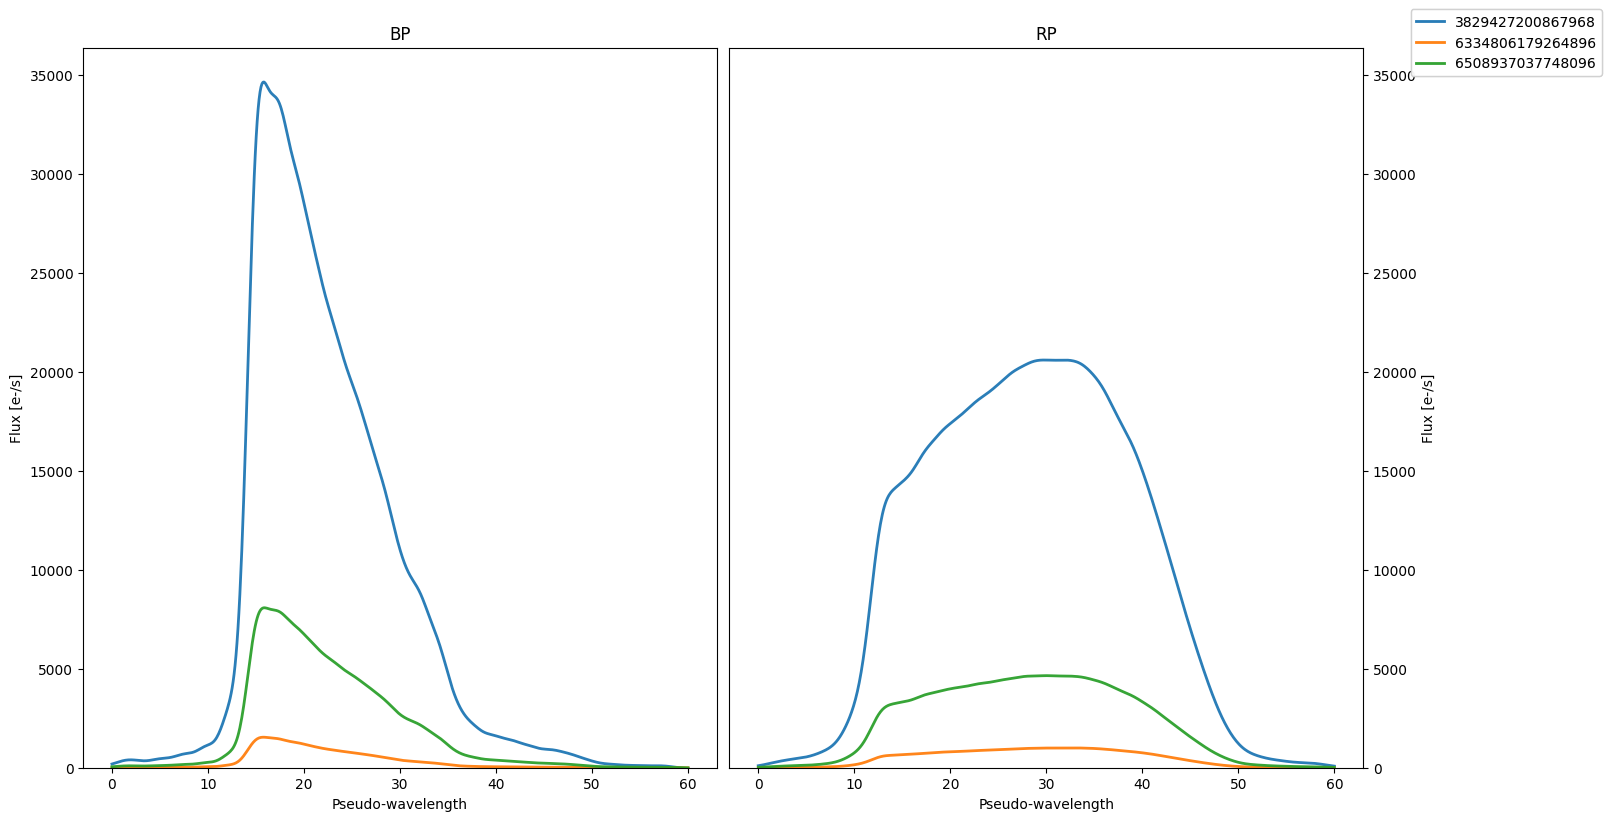

In [10]:
# convert to sampled form:
sampled_spectra, sampling = convert(cdf, save_file = False)
    
# plot to sanity check:
plot_spectra(sampled_spectra, sampling = sampling, multi=True, show_plot=True, output_path="/home/jovyan", legend=True)

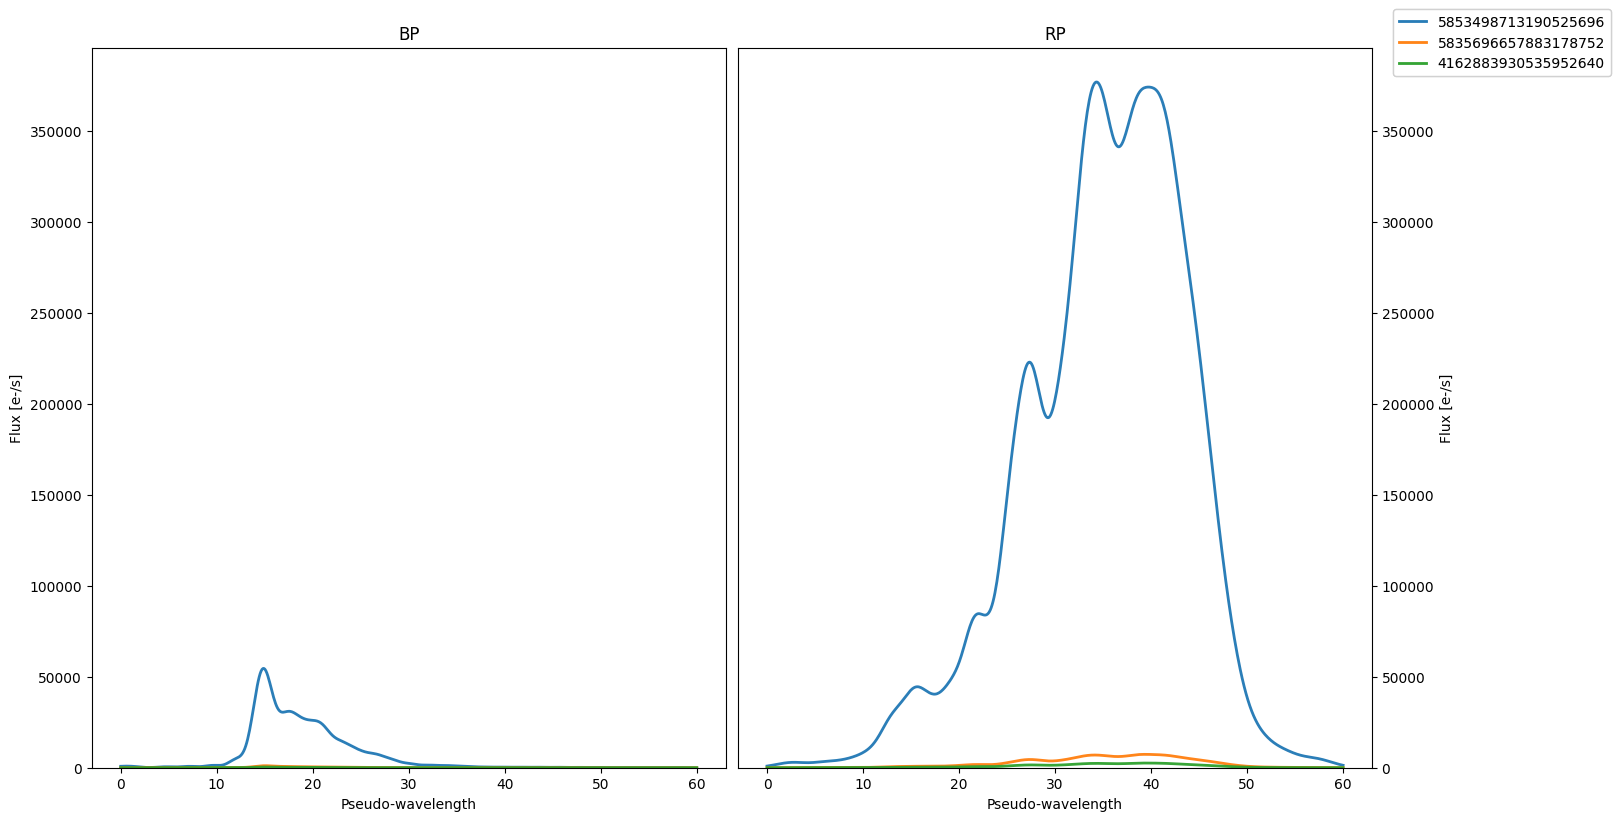

In [11]:
# convert to sampled form:
sampled_spectra, sampling = convert(top3_pdf, save_file = False)
    
# plot to sanity check:
plot_spectra(sampled_spectra, sampling = sampling, multi=True, show_plot=True, output_path="/home/jovyan", legend=True)

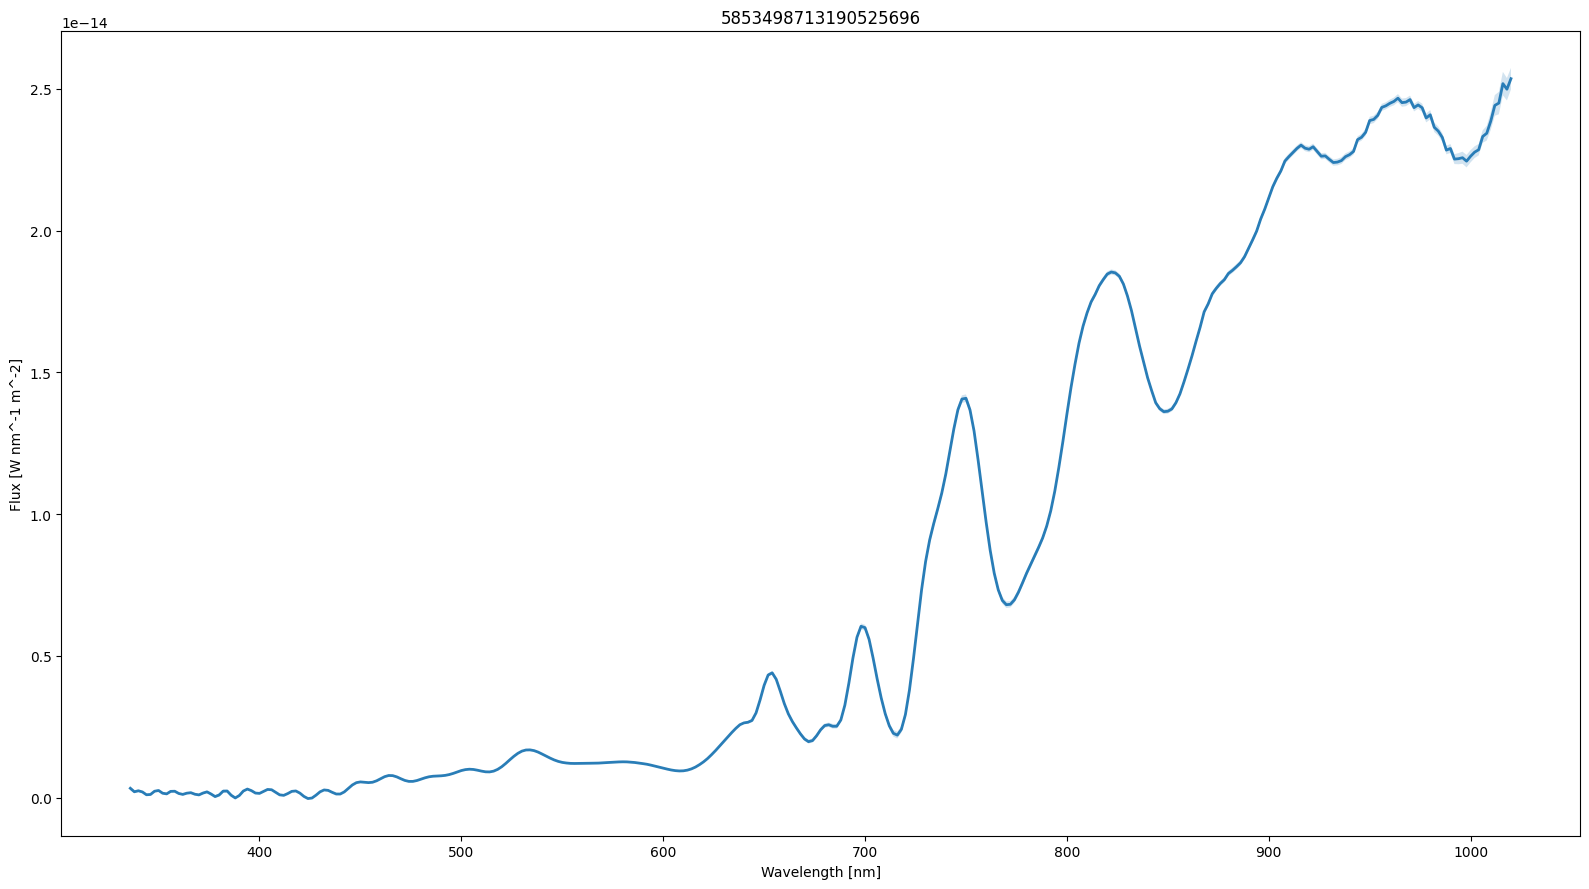

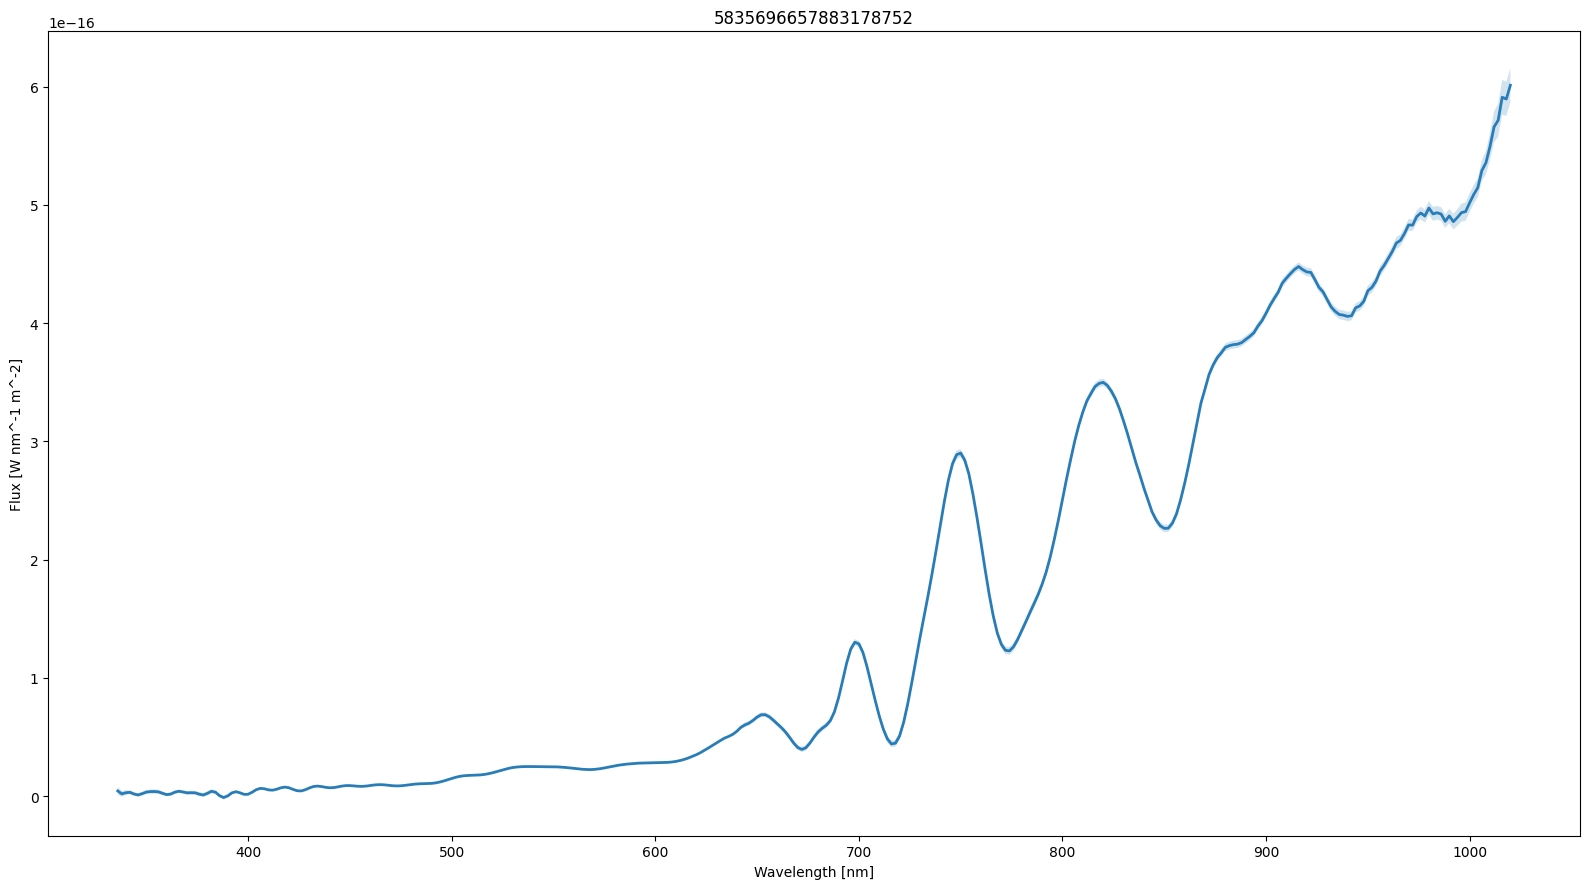

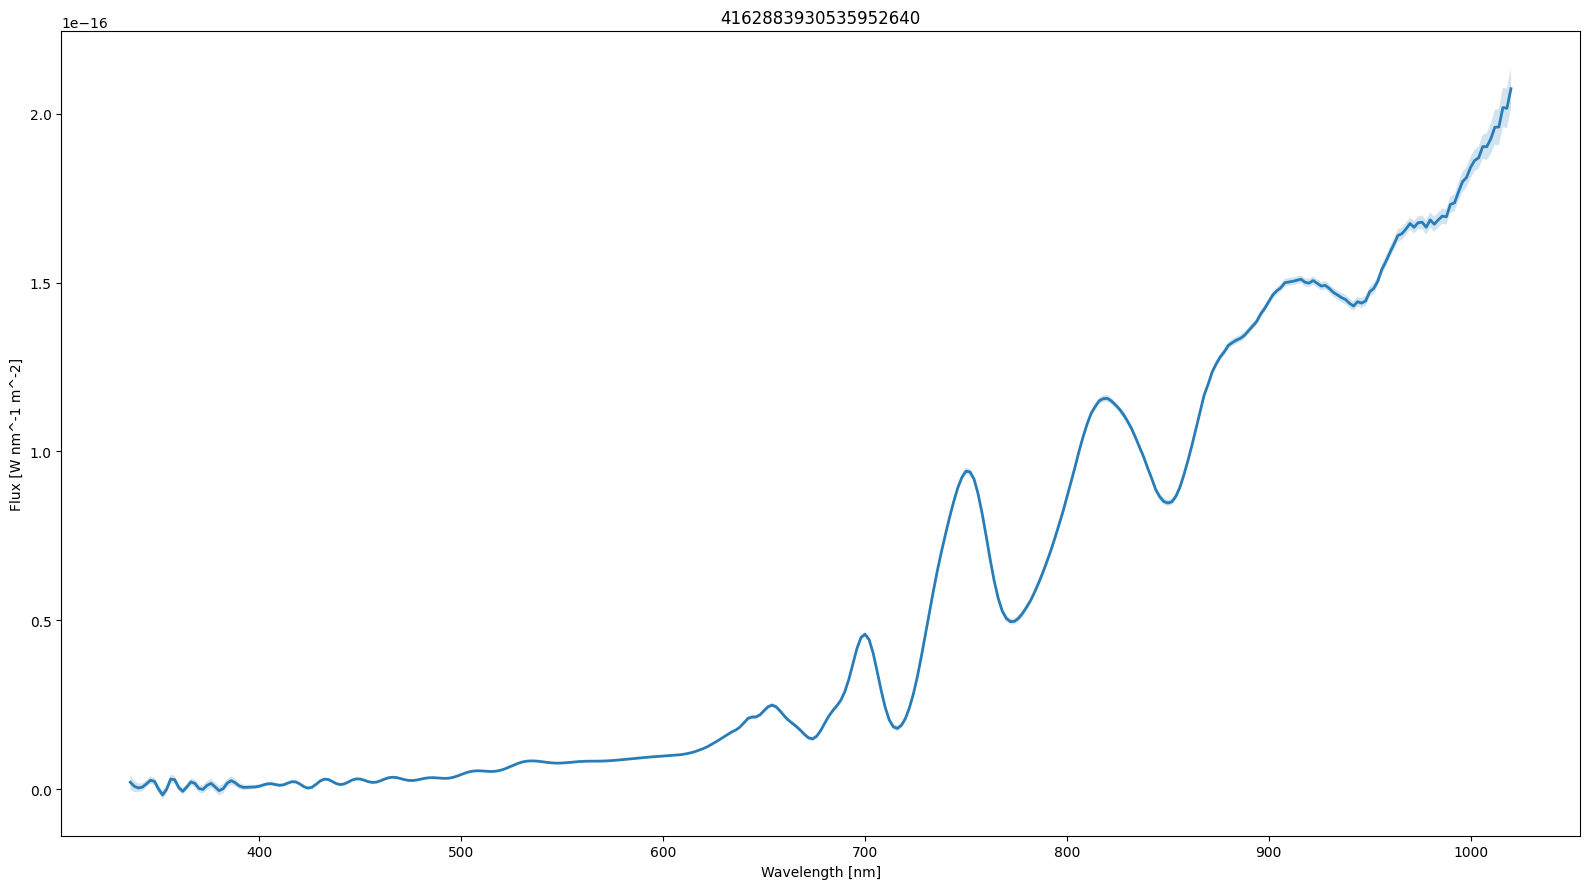

In [12]:
# externally calibrate the spectra
calibrated_spectra, sampling = calibrate(top3_pdf, save_file = False)

# plot the spectra
plot_spectra(calibrated_spectra, sampling = sampling, legend = True)

* [Gaia DR3 XP spectra online documentation](https://gea.esac.esa.int/archive/documentation/GDR3/Data_processing/chap_cu5pho/cu5pho_sec_specProcessing/cu5pho_ssec_specInternCal.html#SSS3)
* [Gaia DR3 spectroscopic data model](https://gea.esac.esa.int/archive/documentation/GDR3/Gaia_archive/chap_datamodel/sec_dm_spectroscopic_tables/)
* [GaiaXPy website](https://gaia-dpci.github.io/GaiaXPy-website/)
* [GaiaXPy API documentation](https://gaiaxpy.readthedocs.io/en/latest/gaiaxpy.html)
* [Vectorised User Defined Functions for PySpark](https://databricks.com/blog/2020/05/20/new-pandas-udfs-and-python-type-hints-in-the-upcoming-release-of-apache-spark-3-0.html)
